# Number theory 7: The number field sieve

*Learning path: number theory, part 7 of 7.* [Index](README.md) · Previous: [The factoring lab](06-factoring-lab.ipynb)

Every record factorization since the 1990s, up to RSA-250 (250 digits, 2020), was done with the **number field
sieve**. Its cost grows like $L(1/3) = e^{1.92 (\ln N)^{1/3} (\ln \ln N)^{2/3}}$, while the quadratic sieve of the
last lessons grows like $L(1/2)$. This lesson builds the method up from one idea and runs Galileo's own (small,
plain) implementation on real numbers. You will see

* why a polynomial $f$ with $f(m) \equiv 0 \pmod N$ gives two worlds that agree modulo $N$,
* how pairs $(a, b)$ that are smooth in **both** worlds are found by a sieve,
* how linear algebra and a square root in a number field turn them into a factor,
* why numbers like $2^{128} + 1$ are much easier (the special number field sieve), and how the algebraic factoring of
  [lesson 3](03-algebraic-factoring.ipynb) can finish the job before any sieving starts,
* an honest race against the quadratic sieve.

## 1. One number, two worlds

The quadratic sieve looks for $x$ with $x^2 \bmod N$ small, so that it splits into small primes. Those numbers are
about $\sqrt N$, which is what makes it slow for large $N$. The number field sieve gets much smaller numbers by
working in two worlds at once.

Take a polynomial $f$ of degree $d$ and a whole number $m$ with $f(m) \equiv 0 \pmod N$. The simplest way: choose
$m \approx N^{1/d}$ and write $N$ in base $m$; the digits are the coefficients, so $f(m) = N$ exactly. Let $\alpha$
be a root of $f$ (a complex number). Numbers $a - b\alpha$ with whole $a, b$ can be added and multiplied like
polynomials in $\alpha$, and replacing $\alpha$ by $m$ keeps every product correct **modulo $N$**, because
$f(\alpha) = 0$ and $f(m) \equiv 0$. So if a set $S$ of pairs has

$$\prod_{S} (a - b m) = X^2 \quad\text{and}\quad \prod_{S} (a - b\alpha) = \beta^2,$$

then $X^2 \equiv \beta(m)^2 \pmod N$, and as in the quadratic sieve $\gcd(X - \beta(m), N)$ is a factor half of the
time.

For $N = 2^{128} + 1$ there is a much better polynomial than base $m$: $2 (2^{128} + 1) = (2^{43})^3 + 2$, so
$f(x) = x^3 + 2$ with $m = 2^{43}$. In the world of $\alpha = \sqrt[3]{-2}$, the size of $a - b\alpha$ is measured by
its **norm** $a^3 + 2 b^3$, a small number. Here is the pair $a = -100$, $b = 1$ in both worlds:

In [1]:
m = 2^43
a = -100; b = 1
factor(a - b*m)
factor(a^3 + 2*b^3)

8796093022208
1
-1 * 2^2 * 3 * 19 * 59 * 97 * 107 * 251^2

> `factor` of a whole number: its prime factorization. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time.

-1 * 2 * 31 * 127^2

> `factor` of a whole number: its prime factorization. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time.

Both sides break into primes below 300: the pair is **smooth on both sides**. The rational side is about $10^{13}$
and the algebraic side about $10^6$, while the quadratic sieve would be looking at numbers near $\sqrt N \approx 10^{19}$.
Smaller numbers are far more likely to be smooth, and that is the whole advantage.

## 2. The whole method on $2^{128} + 1$

`gnfs(N)` runs the number field sieve. Its result is the pair of factors, smaller first, as a row you can use in
the next line; the explanation below it shows each step (`explain = false` hides explanations, here and for every
command). Without a polynomial it tries the special forms that the
algebraic factoring of lesson 3 recognizes ($N$ divides $b^k \pm 1$) and base-$m$ polynomials, and picks the one with
the best score.

In [2]:
gnfs(2^128 + 1)

59649589127497217	5704689200685129054721

> The number field sieve split 340282366920938463463374607431768211457 = 5704689200685129054721 * 59649589127497217 in 1.7e6 work units (631 ms).
>
> ```
> 1. Polynomials considered (score = estimated bits of the two norms + alpha; lower is better):
>       92.9  f(x) = x^3 + 2, m = 8796093022208  [special form: N divides 2^128 + 1, so f(x) = x^3 + 2 with m = 2^43]
>       96.9  f(x) = x^4 + 1, m = 4294967296  [special form: N divides 2^128 + 1, so f(x) = x^4 + 1 with m = 2^32]
>       96.9  f(x) = x^4 + 1, m = 4294967296  [base m, degree 4]
>      100.3  f(x) = x^2 + 1, m = 18446744073709551616  [special form: N divides 2^128 + 1, so f(x) = x^2 + 1 with m = 2^64]
>      102.7  f(x) = x^5 + 4, m = 67108864  [special form: N divides 2^128 + 1, so f(x) = x^5 + 4 with m = 2^26]
> 1. f(x) = x^3 + 2, m = 8796093022208 (special form: N divides 2^128 + 1, so f(x) = x^3 + 2 with m = 2^43): f(m) ≡ 0 mod N
>     typical norms: rational about 10^15, algebraic about 10^12; Murphy alpha 1.73
> 2. Factor bases up to 2653: 383 rational primes, 371 algebraic pairs (p, r) with f(r) ≡ 0 mod p; large primes up to 106120
> 3. Sieved 521 lines b = 1..521 with |a| <= 24726 (25765013 pairs): 20328 candidates, 7633 relations (195 full, 7438 with large primes) [0.51 s]
> 4. After removing relations with a prime nobody else has: 1912 relations with 1865 primes and ideals. Structured elimination (adding relations to remove primes that few of them have): matrix 459 x 438 (2 signs, 24 quadratic characters)
>     linear algebra mod 2: 24 dependencies (subsets whose product is a square on both sides) [0.59 s]
> 5. Square roots: rational side from the exponents, algebraic side at q = 106453 where f splits
>     dependency 1: 992 relations
>     square root found 106453-adically to 1805 digits; its coefficients have about 1715 digits
> 6. X = f'(m) ∏ sqrt(a - b m), Y = β(m): X² ≡ Y² (mod N), gcd(X - Y, N) = 5704689200685129054721 [0.63 s]
> ```

How to read the explanation:

1. **Polynomial.** For $2^{128} + 1$ it picks $x^3 + 2$, $m = 2^{43}$ from the form $2^{128} + 1$.
2. **Factor bases.** On the rational side, the primes $p$ up to a bound $B$. On the algebraic side, the pairs
   $(p, r)$ with $f(r) \equiv 0 \pmod p$: the prime $p$ divides the norm of $a - b\alpha$ exactly when
   $a \equiv b r \pmod p$. (These pairs are the prime ideals of degree one; the norm alone cannot tell which root,
   and it matters.)
3. **Sieve.** For each line $b = 1, 2, \ldots$ and $|a| \le A$, add $\log p$ at every $a \equiv b m \pmod p$ on the
   rational side and every $a \equiv b r \pmod p$ on the algebraic side, exactly like the sieve of Eratosthenes.
   Where both totals come close to the size of the number, check by division. One leftover **large prime** per side
   is allowed; it is useful only if another relation has the same one.
4. **Linear algebra.** Each relation is a vector of exponents mod 2 (plus the signs). Relations that share a rare
   prime are added together first, which shrinks the matrix, then Gaussian elimination finds sets whose exponents
   are all even. Even exponents on the algebraic side are not quite enough for a square in $\mathbb{Z}[\alpha]$
   (units and the class group get in the way), so there are 24 more columns: **quadratic characters**, the
   Legendre symbols $\left(\frac{a - b s}{q}\right)$ for primes $q$ outside the factor base. A real square gives $+1$
   for every one of them. Characters make a square very likely, not certain; if a set still is not a square, the
   square root step notices and moves on to the next set.
5. **Square roots.** The rational one comes from halving the exponents. The algebraic one, $\beta$ with
   $\beta^2 = f'(\alpha)^2 \prod (a - b\alpha)$, is the hard part of the method: Galileo takes a prime $q$ where $f$
   has $d$ roots, takes square roots of the product at each root modulo $q$, lifts them to modulo $q^{k}$ (Hensel's
   lemma, Newton's method for $p$-adic numbers) until $q^k$ is larger than the coefficients of $\beta$, and
   interpolates. The coefficients have thousands of digits, but they are exact. (The factor $f'(\alpha)^2$
   guarantees that $\beta$ has whole-number coefficients.)
6. **gcd.** $X = f'(m) \prod \sqrt{a - b m}$ and $Y = \beta(m)$ satisfy $X^2 \equiv Y^2 \pmod N$. If $X \equiv \pm Y$
   the set was unlucky and the next one is tried.

## 3. When the polynomial factors

Some special forms give a polynomial that is not irreducible. Then the number field sieve has nothing to do: if
$f = g h$ then $f(m) = g(m) h(m)$, and $\gcd(g(m), N)$ often is a factor already. This is exactly the algebraic
factoring of lesson 3. Sophie Germain's identity $x^4 + 4 = (x^2 + 2x + 2)(x^2 - 2x + 2)$ with $x = 2^{20}$ gives
$2^{80} + 4 = 4 (2^{78} + 1)$:

In [3]:
gnfs(2^78 + 1, x^4 + 4, 2^20)

549754765313	549756862465

> The number field sieve split 302231454903657293676545 = 549754765313 * 549756862465 in 0 work units (<1 ms).
>
> ```
> 1. f(x) = x^4 + 4, m = 1048576 (your polynomial): f(m) ≡ 0 mod N
>     f factors over the integers: (x^2 - 2*x + 2) (x^2 + 2*x + 2)
>     gcd(g(m), N) = 549754765313 for the factor g = x^2 - 2*x + 2: done without sieving
> ```

`gnfs(N, f, m)` uses your polynomial; $f(m)$ must be divisible by $N$. That is how one special form can give a
cheap algebraic split while the same idea with an irreducible $f$ powers the sieve.

## 4. Choosing the polynomial

The time of the sieve depends mostly on how large the two norms are. `nfspoly(N)` lists polynomials with a
**score**: the estimated number of bits of both norms over a typical sieve region, plus Murphy's $\alpha$, which
rewards polynomials that have many roots modulo small primes (their values are divisible by small primes more often
than random numbers). Lower is better.

In [4]:
nfspoly(2^128 + 1)

x^3+2	8796093022208	92.9
x^4+1	4294967296	96.9
x^4+1	4294967296	96.9
x^2+1	18446744073709551616	100.3
x^5+4	67108864	102.7
x^6+16	4194304	113.2
x^3+6285202991*x^2+805709614380*x+2208031117835	6979369219251	119.7

> | score | norm bits | alpha | f(x) | m | how |
> |---|---|---|---|---|---|
> | 92.9 | 91.2 | 1.73 | $x^3 + 2$ | 8796093022208 | special form: N divides 2^128 + 1, so f(x) = x^3 + 2 with m = 2^43 |
> | 96.9 | 93.6 | 3.32 | $x^4 + 1$ | 4294967296 | special form: N divides 2^128 + 1, so f(x) = x^4 + 1 with m = 2^32 |
> | 96.9 | 93.6 | 3.32 | $x^4 + 1$ | 4294967296 | base m, degree 4 |
> | 100.3 | 98.7 | 1.56 | $x^2 + 1$ | 18446744073709551616 | special form: N divides 2^128 + 1, so f(x) = x^2 + 1 with m = 2^64 |
> | 102.7 | 101.1 | 1.62 | $x^5 + 4$ | 67108864 | special form: N divides 2^128 + 1, so f(x) = x^5 + 4 with m = 2^26 |
> | 113.2 | 110.5 | 2.64 | $x^6 + 16$ | 4194304 | special form: N divides 2^128 + 1, so f(x) = x^6 + 16 with m = 2^22 |
> | 119.7 | 119.1 | 0.60 | $x^3 + 6285202991*x^2 + 805709614380*x + 2208031117835$ | 6979369219251 | base m, degree 3 |
>
> score = estimated bits of the rational plus algebraic norm over a typical sieve region, plus Murphy's alpha (in bits); lower sieves faster
>
> The value has one row per polynomial: f(x), m and the score; `gnfs(N, r(1, 1), r(1, 2))` sieves with the first.

The degree is a balance. A higher degree makes $m = N^{1/d}$ and so the rational norm smaller, but the algebraic
norm grows like $A^d$. Try two of them on the same number:

In [5]:
gnfs(2^128 + 1, x^4 + 1, 2^32)

59649589127497217	5704689200685129054721

> The number field sieve split 340282366920938463463374607431768211457 = 59649589127497217 * 5704689200685129054721 in 2.2e6 work units (798 ms).
>
> ```
> 1. f(x) = x^4 + 1, m = 4294967296 (your polynomial): f(m) ≡ 0 mod N
>     typical norms: rational about 10^12, algebraic about 10^16; Murphy alpha 3.32
> 2. Factor bases up to 3451: 482 rational primes, 465 algebraic pairs (p, r) with f(r) ≡ 0 mod p; large primes up to 138040
> 3. Sieved 482 lines b = 1..482 with |a| <= 28427 (27404110 pairs): 26630 candidates, 9209 relations (299 full, 8910 with large primes) [0.66 s]
> 4. After removing relations with a prime nobody else has: 2287 relations with 2222 primes and ideals. Structured elimination (adding relations to remove primes that few of them have): matrix 510 x 478 (2 signs, 24 quadratic characters)
>     linear algebra mod 2: 24 dependencies (subsets whose product is a square on both sides) [0.74 s]
> 5. Square roots: rational side from the exponents, algebraic side at q = 138433 where f splits
>     dependency 1: 1072 relations
>     square root found 138433-adically to 1717 digits; its coefficients have about 1593 digits
> 6. X = f'(m) ∏ sqrt(a - b m), Y = β(m): X² ≡ Y² (mod N), gcd(X - Y, N) = 59649589127497217 [0.80 s]
> ```

For a number without a special form, only the base-$m$ polynomials remain, and their coefficients are as large as
$m$:

In [6]:
N = semiprime(40, 1)
nfspoly(N)

4754405852378758586278577751857000165449

> `semiprime`: A balanced semiprime N = p q with exactly that many digits, p and q primes of the same size drawn at random from the seed (default 0); the same seed always gives the same number.

x^4+8722300*x^3+456931343*x^2-927222639*x+1529376589	8301566412	113.2
x^3+1891766625*x^2-276048960581*x+1419330539245	16814442184548	118.1

> | score | norm bits | alpha | f(x) | m | how |
> |---|---|---|---|---|---|
> | 113.2 | 112.3 | 0.91 | $x^4 + 8722300*x^3 + 456931343*x^2 - 927222639*x + 1529376589$ | 8301566412 | base m, degree 4 |
> | 118.1 | 118.7 | -0.63 | $x^3 + 1891766625*x^2 - 276048960581*x + 1419330539245$ | 16814442184548 | base m, degree 3 |
>
> score = estimated bits of the rational plus algebraic norm over a typical sieve region, plus Murphy's alpha (in bits); lower sieves faster
>
> The value has one row per polynomial: f(x), m and the score; `gnfs(N, r(1, 1), r(1, 2))` sieves with the first.

Compare the scores with the special form above: about 113 bits against 93 for $2^{128} + 1$, which has about the
same size. Twenty bits more in the norms means far fewer smooth pairs. That is why the special number field sieve
reaches numbers about 1.5 times as long as the general one with the same work. Serious programs spend hours
searching for good polynomials (Kleinjung's method, root sieving); `nfspoly` only tries a few values of $m$.

### Searching harder: `polyselect`

`polyselect(N, d, generations)` searches more widely, in three steps:

1. **Base $m$:** write $N$ in base $m \approx N^{1/d}$, which gives $f$ with $f(m) = N$.
2. **Root sieve:** rotations $f + (jx + k)(x - m)$ keep the common root $m$ for free. A sieve over $j$ and $k$
   finds the rotation with the most roots modulo small primes, that is the most negative $\alpha$.
3. **Evolution:** a population of candidates (leading coefficient, shift of $m$, rotation) is mutated, and the
   fittest survive by **Murphy's $E$**. $E$ is the average of $\rho(u_f)\,\rho(u_g)$ over the sieve region, where
   Dickman's $\rho(u)$ is the chance that a number of size $B^u$ has no prime factor above $B$. It estimates how
   often both norms are smooth at the same time.

Real sieves use a skewed region: much wider in $a$ than in $b$ when the coefficients of $f$ shrink from $a_0$ to
$a_d$. So the table also shows the best **skew** and the **lognorm**, the size of $F(a, b)$ over that region:

In [7]:
polyselect(N, 4, 20)

x^4+180711*x^3+5953937*x^2-317024952*x+970984702	8303700951

> Polynomial selection for this 40-digit number, degree 4: pairs $f(x)$, $g(x) = x - m$ with $f(m) = N$. Smaller lognorm (size of $F(a, b)$ over the sieve region, at the best skew), more negative $\alpha$ (more roots mod small primes) and larger Murphy $E$ (estimated chance that $F$ and $G$ are both smooth, with bounds $B = 6e5$ and area 3e12) are better. $E$ only compares polynomials for the same $N$.
>
> | step | leading coeff | m shift | rotation j, k | skew | lognorm | α | E |
> |---|---|---|---|---|---|---|---|
> | base m | 1 | 0 | 0, 0 | 2.371e4 | 20.08 | +0.52 | 7.073e-6 |
> | root sieve | 1 | 0 | -3, 15797 | 2.372e4 | 20.08 | -2.59 | 1.378e-5 |
> | generation 0 | 4288 | 0 | 0, 0 | 5.337e1 | 16.25 | -0.23 | 1.656e-5 |
> | generation 3 | 3129 | 41 | 1, 0 | 3.978e1 | 16.10 | -0.38 | 1.826e-5 |
> | generation 6 | 3912 | 0 | 1, 0 | 4.020e1 | 16.11 | -1.56 | 2.103e-5 |
> | generation 9 | 3912 | 0 | 1, 0 | 4.020e1 | 16.11 | -1.56 | 2.103e-5 |
> | generation 12 | 3912 | 0 | 1, 0 | 4.020e1 | 16.11 | -1.56 | 2.103e-5 |
> | generation 15 | 3912 | 0 | 1, 0 | 4.020e1 | 16.11 | -1.56 | 2.103e-5 |
> | generation 18 | 3912 | 0 | 1, 0 | 4.020e1 | 16.11 | -1.56 | 2.103e-5 |
> | generation 20 | 3912 | 0 | 1, 0 | 4.020e1 | 16.11 | -1.56 | 2.103e-5 |
>
> Best E is 3.0 times that of plain base m. The best pair:
>
> * $f(x) = $ `3912*x^4 + 7841*x^3 + 35699588*x^2 - 1276363291*x + 78770439`
> * $g(x) = x - m$ with $m = $ `1049963861`
> * check: $f(m) - N = 0$
>
> Galileo's teaching sieve `gnfs` wants a monic $f$ and sieves a rectangle without skew ($|a| \le 30000$, $b$ up to a few thousand), so the best pair above (leading coefficient 3912) is not the one for it. A second search keeps $f$ monic and scores with the sieve's own estimate (bits of both norms over its rectangle plus $\alpha$; lower is better). Best monic pair: score 106.3, against 113.6 for the polynomial `gnfs` picks by itself at this degree:
>
> `gnfs(4754405852378758586278577751857000165449, x^4 + 180711*x^3 + 5953937*x^2 - 317024952*x + 970984702, 8303700951)`
>
> The value is the best monic pair as [f(x) m], ready for `gnfs(N, r(1, 1), r(1, 2))`.

The search mostly improves $\alpha$ and the leading coefficient. Galileo's own sieve wants a monic $f$ and sieves a
rectangle without skew, so `polyselect` also runs a monic search scored by `gnfs`'s own estimate, and prints a
`gnfs(...)` line to paste. On this 40-digit number, `gnfs(N)` with its own polynomial took $1.6 \cdot 10^8$ work units,
and with the polynomial from `polyselect` $1.6 \cdot 10^7$, ten times less. On another 38-digit semiprime the gain was
3.7 times. Run both and compare; each takes from seconds to a few minutes.

The same search on RSA-100 (the 100-digit RSA challenge number, factored in 1991) raises $E$ about twentyfold over
plain base $m$:

In [8]:
load(RSA);
polyselect(RSA100, 4, 30)

x^4-228485*x^3-1071664697503878881052357*x^2+576378058810742212313568*x-2943031145533419262701317	6246644847868435165516064

> Polynomial selection for this 100-digit number, degree 4: pairs $f(x)$, $g(x) = x - m$ with $f(m) = N$. Smaller lognorm (size of $F(a, b)$ over the sieve region, at the best skew), more negative $\alpha$ (more roots mod small primes) and larger Murphy $E$ (estimated chance that $F$ and $G$ are both smooth, with bounds $B = 1e7$ and area 1e16) are better. $E$ only compares polynomials for the same $N$.
>
> | step | leading coeff | m shift | rotation j, k | skew | lognorm | α | E |
> |---|---|---|---|---|---|---|---|
> | base m | 1 | 0 | 0, 0 | 3.913e11 | 53.32 | +1.87 | 4.482e-11 |
> | root sieve | 1 | 0 | 4, 12472 | 3.913e11 | 53.32 | -2.63 | 4.880e-10 |
> | generation 0 | 8415 | 0 | 0, 0 | 6.851e8 | 49.66 | -0.37 | 6.503e-10 |
> | generation 5 | 8415 | 0 | 0, 5984 | 6.851e8 | 49.66 | -1.17 | 8.096e-10 |
> | generation 10 | 8415 | 0 | 0, 13467 | 6.851e8 | 49.66 | -1.38 | 8.563e-10 |
> | generation 15 | 8415 | 0 | 0, 21129 | 6.851e8 | 49.66 | -1.54 | 8.936e-10 |
> | generation 20 | 8415 | 233 | 0, 6138 | 6.851e8 | 49.66 | -1.66 | 9.229e-10 |
> | generation 25 | 8415 | 233 | 0, 6138 | 6.851e8 | 49.66 | -1.66 | 9.229e-10 |
> | generation 30 | 8415 | 233 | 0, 6138 | 6.851e8 | 49.66 | -1.66 | 9.229e-10 |
>
> Best E is 20.6 times that of plain base m. The best pair:
>
> * $f(x) = $ `8415*x^4 - 7838785*x^3 - 27644306950066984844085*x^2 + 305710492777574968734844*x - 4003113617433822761828907845`
> * $g(x) = x - m$ with $m = $ `652203739879557108236556`
> * check: $f(m) - N = 0$
>
> Galileo's teaching sieve `gnfs` wants a monic $f$ and sieves a rectangle without skew ($|a| \le 30000$, $b$ up to a few thousand), so the best pair above (leading coefficient 8415) is not the one for it. A second search keeps $f$ monic and scores with the sieve's own estimate (bits of both norms over its rectangle plus $\alpha$; lower is better). Best monic pair: score 210.9, against 211.7 for the polynomial `gnfs` picks by itself at this degree:
>
> `gnfs(1522605027922533360535618378132637429718068114961380688657908494580122963258952897654000350692006139, x^4 - 228485*x^3 - 1071664697503878881052357*x^2 + 576378058810742212313568*x - 2943031145533419262701317, 6246644847868435165516064)`
>
> The value is the best monic pair as [f(x) m], ready for `gnfs(N, r(1, 1), r(1, 2))`.

Two cautions. First, $E$ only compares polynomials for the same $N$ and the same sieve: a polynomial chosen for a
skewed lattice sieve can be worse in a rectangle, which is why there are two searches. Second, a better polynomial
saves a constant factor, typically tens of percent at record sizes, but it does not change how the cost grows with
$N$. Evolution or a neural network could tune the search; they cannot remove the $L_N[1/3]$ in the running time.

## 5. General numbers and the race against the quadratic sieve

Here is the general number field sieve on a 30-digit semiprime:

In [9]:
gnfs(semiprime(30, 1))

746427731226967	766018181296783

> The number field sieve split 571777213143965220843759947161 = 746427731226967 * 766018181296783 in 2.1e6 work units (1.42 s).
>
> ```
> 1. Polynomials considered (score = estimated bits of the two norms + alpha; lower is better):
>       94.9  f(x) = x^4 + 20589*x^3 - 2631874*x^2 - 3691089*x + 13042414, m = 27493209  [base m, degree 4]
>      100.0  f(x) = x^3 + 7160742*x^2 + 987349042*x + 673677296, m = 8297566417  [base m, degree 3]
> 1. f(x) = x^4 + 20589*x^3 - 2631874*x^2 - 3691089*x + 13042414, m = 27493209 (base m, degree 4): f(m) ≡ 0 mod N
>     typical norms: rational about 10^10, algebraic about 10^19; Murphy alpha -1.48
> 2. Factor bases up to 4620: 623 rational primes, 595 algebraic pairs (p, r) with f(r) ≡ 0 mod p; large primes up to 184800
> 3. Sieved 163 lines b = 1..163 with |a| <= 30000 (9780163 pairs): 24201 candidates, 10291 relations (483 full, 9808 with large primes) [0.73 s]
> 4. After removing relations with a prime nobody else has: 2228 relations with 2164 primes and ideals. Structured elimination (adding relations to remove primes that few of them have): matrix 497 x 465 (2 signs, 24 quadratic characters)
>     linear algebra mod 2: 24 dependencies (subsets whose product is a square on both sides) [0.82 s]
> 5. Square roots: rational side from the exponents, algebraic side at q = 185167 where f splits
>     dependency 1: 1058 relations
>     square root found 185167-adically to 4567 digits; its coefficients have about 3028 digits
>     X ≡ ±Y: trivial, next dependency
>     dependency 2: 1026 relations
>     square root found 185167-adically to 4419 digits; its coefficients have about 2922 digits
> 6. X = f'(m) ∏ sqrt(a - b m), Y = β(m): X² ≡ Y² (mod N), gcd(X - Y, N) = 746427731226967 [1.42 s]
> ```

And the scoreboard of lesson 6, with `"nfs"` as a method:

qs	20	1	1	0.064398826
qs	24	1	1	0.076763694
qs	28	1	1	0.066069898
qs	32	1	1	0.081359088
nfs	20	1	1	0.142471282
nfs	24	1	1	0.502497006
nfs	28	1	1	0.936146832
nfs	32	1	1	3.281160389

> **Scoreboard**: balanced semiprimes (p and q of the same size, seeds 0 to 0), at most 30.00 s per run.
>
> | method | digits | solved | median work | median time |
> |---|---|---|---|---|
> | `qs` | 20 | 1/1 | 3.5e4 | 64 ms |
> | `qs` | 24 | 1/1 | 5.6e4 | 77 ms |
> | `qs` | 28 | 1/1 | 5.3e4 | 66 ms |
> | `qs` | 32 | 1/1 | 1.7e5 | 81 ms |
> | `nfs` | 20 | 1/1 | 1.5e5 | 142 ms |
> | `nfs` | 24 | 1/1 | 3.6e5 | 502 ms |
> | `nfs` | 28 | 1/1 | 1.3e6 | 936 ms |
> | `nfs` | 32 | 1/1 | 5.8e6 | 3.28 s |
>
> **How the cost grows** (time; for reference: trial division N^0.5, Hart N^0.33, rho and SQUFOF N^0.25, quadratic sieve L(1/2) with constant 1, number field sieve L(1/3) with constant 1.92):
>
> - `qs`: cost grows like N^0.006 (fit on 4 sizes); L(1/2) constant 0.04, L(1/3) constant 0.07; best fit: N^a (few sizes: the models are hard to tell apart)
> - `nfs`: cost grows like N^0.109 (fit on 4 sizes); L(1/2) constant 0.67, L(1/3) constant 1.30; best fit: N^a (few sizes: the models are hard to tell apart)
>
> The value has one row per method and size: method, digits, solved, trials, cost (seconds, or work units in the browser).

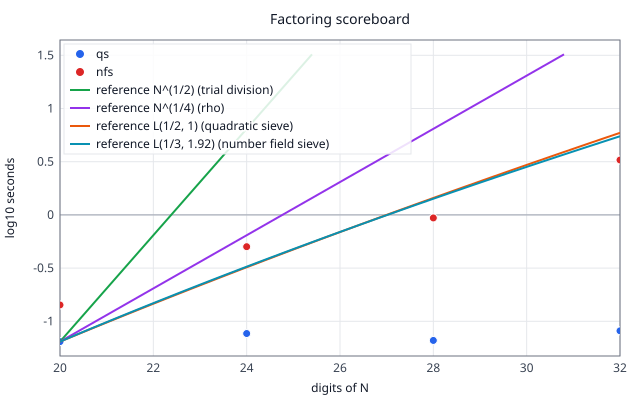

> `scoreplot`: Plots scoreboard results: log10 of the cost against the number of digits, one series of points per method, plus reference curves for N^(1/2), N^(1/4), L(1/2, 1) and L(1/3, 1.92) drawn through the first point (only where they stay near the data).

In [10]:
sb = scoreboard(["qs" "nfs"], 20:4:32, 1, 30)
scoreplot(sb)

The quadratic sieve wins at these sizes, by a factor of about 30. That is not a flaw of the lesson: also in serious
implementations the number field sieve only overtakes the quadratic sieve at around 100 digits, because its steps
(two factor bases, characters, the algebraic square root) cost more and its advantage, the $1/3$ in the exponent,
grows slowly. With this code on a normal computer:

* the 51-digit part of $2^{193} - 1$ (special form, polynomial $x^4 - 8$): about 7 s, quadratic sieve about 2 s,
* the Fermat number $2^{256} + 1$ (78 digits, special form $x^5 + 16$, $m = 2^{52}$): the special number field
  sieve splits it as $1238926361552897 \times p_{62}$ in under 3 minutes, while the quadratic sieve of lesson 6 does
  not finish in 5 minutes.

Larger numbers need what real programs (CADO-NFS, msieve) add: lattice sieving instead of line sieving, two or three
large primes per side, block Lanczos or block Wiedemann for matrices with millions of rows, and good polynomials. With
those, RSA-250 took about 2700 core-years.

## Summary

* Two worlds: $\mathbb{Z}$ and $\mathbb{Z}[\alpha]$ with $f(\alpha) = 0$, joined by $\alpha \mapsto m$ modulo $N$.
* A relation is a pair $(a, b)$ with $a - bm$ and the norm $b^d f(a/b)$ both smooth; a sieve finds them.
* Linear algebra mod 2, with signs and quadratic characters, picks a square on both sides; the algebraic square root
  is computed $q$-adically.
* Special forms give tiny polynomials (SNFS); forms whose polynomial factors are split by algebra alone.
* `gnfs(N)`, `gnfs(N, f, m)`, `nfspoly(N)`, and the method `"nfs"` in `labrun` and `scoreboard`.
* `polyselect(N, d)`: base $m$, a root sieve for $\alpha$ and an evolutionary search by Murphy's $E$, plus a monic
  pair for `gnfs`.

**Try it:** run `gnfs(2^128 + 1, x^5 + 4, 2^26)` (degree 5) and compare the work with degree 3 and 4. Run
`gnfs(10^40 + 1, x^5 + 1, 10^8)` and explain what happens (what is $x^5 + 1$ over the integers?). Compare
`labrun("nfs", 2^128 + 1)` with `labrun("ecm", 2^128 + 1)`: why does ECM win here, where one factor has only 17
digits?

## Sources

1. A. K. Lenstra and H. W. Lenstra (eds.), *The Development of the Number Field Sieve*, Lecture Notes in Math. 1554, Springer (1993).
2. J. P. Buhler, H. W. Lenstra and C. Pomerance, "Factoring integers with the number field sieve", in [1], 50–94.
3. C. Pomerance, "A tale of two sieves", *Notices of the AMS* 43 (1996) 1473–1485.
4. A. K. Lenstra, H. W. Lenstra, M. S. Manasse and J. M. Pollard, "The factorization of the ninth Fermat number", *Math. Comp.* 61 (1993) 319–349.
5. R. P. Brent and J. M. Pollard, "Factorization of the eighth Fermat number", *Math. Comp.* 36 (1981) 627–630.
6. M. E. Briggs, *An Introduction to the General Number Field Sieve*, master's thesis, Virginia Tech (1998).
7. B. A. Murphy, *Polynomial Selection for the Number Field Sieve Integer Factorisation Algorithm*, PhD thesis, Australian National University (1999).
8. P. L. Montgomery, "Square roots of products of algebraic numbers", *Proc. Symp. Applied Math.* 48 (1994) 567–571; J.-M. Couveignes, "Computing a square root for the number field sieve", in [1], 95–102.
9. F. Boudot, P. Gaudry, A. Guillevic, N. Heninger, E. Thomé and P. Zimmermann, "Comparing the difficulty of factorization and discrete logarithm: a 240-digit experiment", *CRYPTO 2020*; the RSA-250 announcement (2020).
10. R. Crandall and C. Pomerance, *Prime Numbers: A Computational Perspective*, 2nd ed., Springer (2005), section 6.2.
11. T. Kleinjung, "On polynomial selection for the general number field sieve", *Mathematics of Computation* 75 (2006) 2037–2047.
12. S. Bai, C. Bouvier, A. Kruppa and P. Zimmermann, "Better polynomials for GNFS", *Mathematics of Computation* 85 (2016) 861–873 (root sieve and size optimization in CADO-NFS).